In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
import pandas as pd
from scipy.ndimage import gaussian_filter
import matplotlib as mpl

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
import matplotlib.colors as mcolors
import Plot

In [2]:
import matplotlib.transforms as mtransforms

def add_lat_labels(ax, lats=(-60, -30, 0, 30, 60), pad=3, fontsize=8):
    lon_0 = ax.projection.proj4_params.get('lon_0', 0.0)
    trans = mtransforms.offset_copy(ax.transData, fig=ax.figure,
                                    x=-pad, y=0, units='points')
    for lat in lats:
        x, y = ax.projection.transform_point(lon_0 - 179.99, lat, ccrs.PlateCarree())
        suffix = 'N' if lat > 0 else 'S' if lat < 0 else ''
        ax.text(x, y, f'{abs(lat)}°{suffix}', transform=trans,
                ha='right', va='center', fontsize=fontsize, clip_on=False)

def add_graticule(ax, lat_labels=False):
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=False,
        linewidth=0.6, color='gray', alpha=0.8, linestyle=':', zorder=20
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    gl.top_labels = gl.right_labels= gl.left_labels = False
    gl.bottom_labels = lat_labels
    gl.xlabel_style = {'size': 7}
    gl.ylabel_style = {'size': 7}
    gl.xpadding = 1.5 
    return gl

In [3]:
ds_exp = [
    ['CMIP6', 'CMIP6_ipopos', 'CMIP6_iponeg',], 
    [None, 'CMIP6_amopos', 'CMIP6_amoneg',], 
    ['EXT', 'EXT_ipopos', 'EXT_iponeg',], 
    [None, 'EXT_amopos', 'EXT_amoneg',], 
]
labels = [
    ['CMIP6-no', 'CMIP6-posIPO', 'CMIP6-negIPO',], 
    [None, 'CMIP6-posAMO', 'CMIP6-negAMO',], 
    ['EXT-no', 'EXT-posIPO', 'EXT-negIPO',], 
    [None, 'EXT-posAMO', 'EXT-negAMO',], 
]
numbers = [
    ['a', 'c', 'g'],
    [None,'d', 'h'],
    ['b', 'e', 'i'],
    [None,'f', 'j']
]
labels = [
    ['CMIP6 \N{MINUS SIGN} HIST', 'CMIP6-posIPO \N{MINUS SIGN} CMIP6', 'CMIP6-negIPO \N{MINUS SIGN} CMIP6',], 
    [None, 'CMIP6-posAMO \N{MINUS SIGN} CMIP6', 'CMIP6-negAMO \N{MINUS SIGN} CMIP6',], 
    ['EXT \N{MINUS SIGN} HIST', 'EXT-posIPO  \N{MINUS SIGN} EXT', 'EXT-negIPO  \N{MINUS SIGN} EXT',], 
    [None, 'EXT-posAMO  \N{MINUS SIGN} EXT', 'EXT-negAMO  \N{MINUS SIGN} EXT',], 
]

In [6]:
ds1 = xr.open_dataset("Figure12_1.nc")
ds2 = xr.open_dataset("Figure12_2.nc")

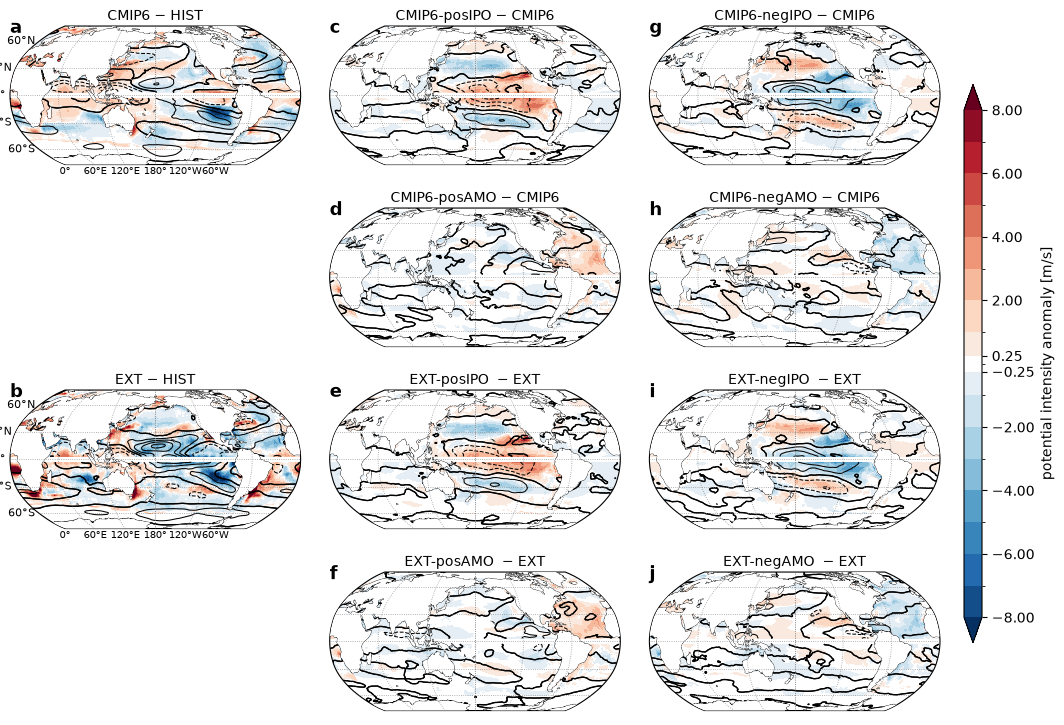

In [7]:
# PI&VWS, Hadley-no - HIST, CMIP6-no - HIST, IPOs&AMOs - no
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(12, 9.3), 
                        subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})
plt.subplots_adjust(hspace=0.07, wspace=0.1)
mpl.rcParams['hatch.linewidth']=0.5
sig_thr1=0.1; sig_thr2=0.1

# cmap for PI
cmap1, levels1, norm1 = Plot.def_colormap(max=8, interval=1, white=0.25, cmap='RdBu_r')
levels2_ws = np.arange(-30, 30+1.5, 1.5)
levels3_ws = np.arange(-30, 30+1.5, 1.5)

for irow in range(4):
    for icol in range(3):
        ax_now = axs[irow,icol]
        if numbers[irow][icol] is None:
            ax_now.axis('off')
            continue
            
        if icol==0:
            ds_now = ds1[f'PI_{ds_exp[irow][icol]}'] - ds1['PI_hist']
            ds_now = ds_now.sel(lat=slice(-80, 80))
            ds_now.loc[dict(lat=slice(-3, 3))] = np.nan
            ds_now2 = ds2[f'ws_{ds_exp[irow][icol]}'] - ds2['ws_hist']
            ds_now2 = ds_now2.sel(lat=slice(-80, 80))
            ds_now2.loc[dict(lat=slice(-3, 3))] = np.nan            
        elif icol!=0:
            ds_now = ds1[f'PI_{ds_exp[irow][icol]}'] - ds1[f'PI_{ds_exp[(irow//2)*2][0]}']
            ds_now = ds_now.sel(lat=slice(-80, 80))
            ds_now.loc[dict(lat=slice(-3, 3))] = np.nan
            ds_now2 = ds2[f'ws_{ds_exp[irow][icol]}'] - ds2[f'ws_{ds_exp[(irow//2)*2][0]}']
            ds_now2 = ds_now2.sel(lat=slice(-80, 80))
            ds_now2.loc[dict(lat=slice(-3, 3))] = np.nan
        ds_now2.plot.contour(
            ax=ax_now, levels=levels2_ws if icol==0 else levels3_ws, 
            colors='black', linewidths=0.75, 
            transform=ccrs.PlateCarree(), add_colorbar=False, 
        )
        ds_now2.plot.contour(
            ax=ax_now, levels=[0], colors='black', linewidths=1.0, 
            transform=ccrs.PlateCarree(), add_colorbar=False, 
        )
            
        p = ds_now.plot.pcolormesh(
            ax=ax_now, levels=levels1, cmap=cmap1, norm=norm1, extend='both',
            add_colorbar=False, transform=ccrs.PlateCarree(), 
        )
        
        ax_now.annotate(
            numbers[irow][icol], xy=(0, 1.05), xycoords='axes fraction',
            fontsize=13, fontweight='bold', ha='left', va='top'
        )
        ax_now.coastlines(linewidth=0.5)
        ax_now.add_feature(cfeature.LAND, facecolor="white", zorder=10)
        ax_now.set_title(None)
        ax_now.text(0.5, 1.02, labels[irow][icol], transform=ax_now.transAxes, fontsize=10, ha='center', va='bottom')
        add_graticule(ax_now, lat_labels=(icol==0))
        if icol==0:
            add_lat_labels(ax_now)

cax = fig.add_axes([0.92, 0.2, 0.015, 0.6])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(p, cax=cax, orientation='vertical', extend='both', spacing='proportional', 
                   ticks=[-8, -6, -4, -2, -0.25, 0.25, 2, 4, 6, 8])
cbar.set_label('potential intensity anomaly [m/s]')
# plt.savefig(f"Figure12.png", dpi=300, bbox_inches='tight',pad_inches=0.28)